# Khảo sát & Kiểm toán Dữ liệu CarbonGlobe (Tuần 1)

Kiểm tra cấu trúc mảng `.npz`/`.npy` (`res_train4_test8.npz`, `data_stats.npz`, `mask2d.npy`), đo bộ nhớ RAM, thống kê NaN/Inf và phân phối 7 biến mục tiêu `TREE_BAND`.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

from src.dataset import TREE_BAND, read_pipeline_config, load_ml_ready_npz, load_stats, load_mask2d
from src.profiling import audit_array, audit_targets_summary
from src.run_sprint1_2 import create_synthetic_carbonglobe_files

cfg = read_pipeline_config(ROOT / "configs/pipeline.yaml")
raw_dir = ROOT / cfg["paths"]["raw_dir"]
glob_dir = raw_dir / cfg["paths"]["global_subdir"]
stat_dir = raw_dir / cfg["paths"]["stats_subdir"]

if not (glob_dir / cfg["carbonglobe"]["ml_ready_file"]).exists():
    print("Chưa có file Kaggle thật -> sinh dữ liệu mô phỏng chuẩn CarbonGlobe để kiểm toán.")
    create_synthetic_carbonglobe_files(raw_dir, seed=cfg["seed"])

data = load_ml_ready_npz(glob_dir, cfg["carbonglobe"]["ml_ready_file"], max_sites=cfg["subset"]["max_sites"])
stats = load_stats(stat_dir, cfg["carbonglobe"]["stats_file"])
mask2d = load_mask2d(stat_dir, cfg["carbonglobe"]["mask_file"])
print("x_train:", data["x_train"].shape, "| y_train:", data["y_train"].shape, "| mask2d:", mask2d.shape)

x_train: (30, 40, 12, 136) | y_train: (15, 30, 41, 12, 7) | mask2d: (360, 720)


In [2]:
audit_df = pd.DataFrame([
    audit_array(data["x_train"], "x_train"),
    audit_array(data["y_train"], "y_train"),
])
display(audit_df)

target_df = pd.DataFrame(audit_targets_summary(data["y_train"], TREE_BAND)).T
display(target_df)

      name                shape    dtype  memory_mb  nan_count  inf_count  nan_ratio      min        max     mean      std
0  x_train    [30, 40, 12, 136]  float32      7.834          1          0   0.000001 -10.4287    40.0362  15.0032   4.9998
1  y_train  [15, 30, 41, 12, 7]  float32      6.199          0          0   0.000000 -25.6538  5000.0000  50.0215  15.5150
        nan_count      min      p50      p95        max     mean      std
height        0.0 -20.8386  50.0764  74.6272   113.6776  50.0517  14.9838
agb           0.0 -11.9616  50.0022  74.6260  5000.0000  49.9912  18.3323
soil          0.0 -16.3994  50.0712  74.7523   116.1886  50.0616  14.9950
lai           0.0 -18.1864  49.9568  74.5967   122.8726  49.9628  14.9683
gpp           0.0 -14.7051  49.9244  74.6319   120.1454  49.9786  15.0142
npp           0.0 -25.6538  50.0415  74.7076   129.6776  50.0458  14.9517
rh            0.0 -18.8345  50.0714  74.8125   119.1340  50.0587  15.0510


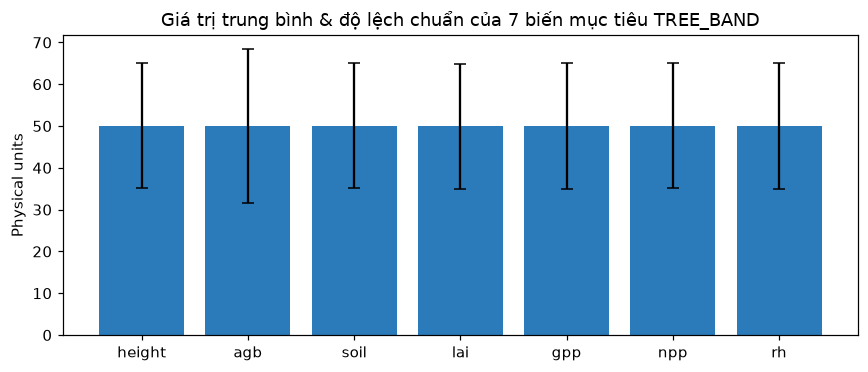

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(target_df.index, target_df["mean"], yerr=target_df["std"], capsize=4, color="#2b7bba")
ax.set_title("Giá trị trung bình & độ lệch chuẩn của 7 biến mục tiêu TREE_BAND")
ax.set_ylabel("Physical units")
plt.tight_layout()
plt.show()